# Measured Intrinsic Wavefront (MIW): OCS / CCS map reader

**Author:** Aaron Roodman &nbsp;|&nbsp; **Purpose:** read and plot the telescope-fixed (OCS) and
camera-fixed (CCS) Measured Intrinsic Wavefront maps for the Rubin AOS.

This is a standalone reader for the `intrinsic_split_maps.parquet` product. It needs only
`numpy`, `matplotlib`, `astropy`, and (for the optional lookup helper) `scipy` — **no LSST stack**
— so it can be used directly in the AOS online system.

### What the file contains
`intrinsic_split_maps.parquet` is an astropy Table on a regular focal-plane disk grid:

| column | meaning |
|---|---|
| `thx_deg`, `thy_deg` | field angle (degrees), OCS frame |
| `Z{j}_OCS` | telescope-fixed MIW for Noll Zernike *j* (µm) |
| `Z{j}_CCS` | camera-fixed MIW for Noll Zernike *j* (µm) |

Each measured map at rotator angle θ is modelled as `Z(r,φ) = O(r,φ) + C(r, φ - s·θ)`:
`O` is the telescope-fixed (OCS) part, `C` is the camera-fixed (CCS) part that rotates with the
Camera Rotator. For Zernikes fit OCS-only, `Z{j}_CCS` is identically zero. The table `.meta`
records the rotator angles used (`thetas_deg`), any `rotator_select` subset, the `ocs_only`
Zernikes, the rotation sign `s`, and `build_from`.

## 1. Parameters

In [1]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from scipy.interpolate import LinearNDInterpolator
from rubinwork.products import catalog

# A catalog MIW build: `python -m rubinwork.products.catalog list miw` shows them.
# d12-A_50_34_i_5rot@20261025 is the Danish 1.2 build with the fixed bad_fit cut.
miw_variant = "d12-A_50_34_i_5rot"
miw_build = "20261025"            # or "current"
maps_path = catalog.path("miw", miw_variant, miw_build) / "intrinsic_split_maps.parquet"
# Or a file outside the catalog, e.g. the staged v1 calibration:
# maps_path = "/sdf/home/r/roodman/notebooks/rubin-work/aos/calibration/miw/intrinsic_split_maps_v1.parquet"

zernikes = "all"        # "all", or a list of Noll indices e.g. [4, 5, 6, 7, 8]
fp_radius_deg = 1.75    # focal-plane radius for plot limits (deg)
pct = 98                # color scale percentile (per Zernike)
z4_rotator_deg = [0.0]  # camera rotator angles (deg) for the Z4 OCS + CCS maps

# CCD height term of Z4 CCS, as in the MIW build and the calibration tables
height_map_dir = "/sdf/group/rubin/u/roodman/LSST/packages/batoid_rubin_data"
height_to_z4 = 15.0     # µm of Z4 per mm of CCD height
n_ccd_grid = 48         # samples per side of each CCD (about 0.0046 deg spacing)
ccd_lim_deg = 1.9       # plot limit (deg) for the CCD-resolution Z4 maps, to show the CWFS

## 2. Read the maps

In [2]:
t = Table.read(maps_path, format="parquet")
thx = np.asarray(t["thx_deg"], dtype=float)
thy = np.asarray(t["thy_deg"], dtype=float)

# discover the Zernikes present from the Z{j}_OCS columns
js = sorted({int(m.group(1)) for c in t.colnames
             for m in [re.match(r"Z(\d+)_OCS$", c)] if m})
if zernikes != "all":
    js = [j for j in js if j in zernikes]
ocs_only = set(int(j) for j in (t.meta.get("ocs_only") or []))

print(f"{len(thx)} field points;  Zernikes available: {js}")
print("metadata:")
for k, v in t.meta.items():
    print(f"  {k}: {v}")

3985 field points;  Zernikes available: [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 22, 23, 24, 25, 26]
metadata:
  rotation_sign: 1
  degen_assignment: ocs
  thetas_deg: [-59.884, -14.963, 0.066, 14.709, 59.748]
  n_bins_used: 5
  rotator_select: [[-65.0, -55.0], [-20.0, -10.0], [-3.0, 3.0], [10.0, 20.0], [55.0, 65.0]]
  ocs_only: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 22, 23, 24, 25, 26]
  build_from: pathA_50_34_i
  null_tol: 0.01
  null_weight: 0.01
  min_ring_coverage: 0.5


## 3. Helper: focal-plane map

In [3]:
def _lattice():
    """Index of each field point on the maps' regular (thx, thy) lattice."""
    step = np.min(np.diff(np.unique(np.round(thx, 6))))
    ix = np.rint((thx - thx.min()) / step).astype(int)
    iy = np.rint((thy - thy.min()) / step).astype(int)
    xe = thx.min() + step * (np.arange(ix.max() + 2) - 0.5)
    ye = thy.min() + step * (np.arange(iy.max() + 2) - 0.5)
    return ix, iy, xe, ye, step


lat_ix, lat_iy, lat_xe, lat_ye, lat_step = _lattice()
print(f"maps lattice: {lat_xe.size - 1} x {lat_ye.size - 1} cells, {lat_step:.4f} deg per cell")


def _frame(ax, title, lim=None):
    lim = fp_radius_deg if lim is None else lim
    ax.add_patch(plt.Circle((0, 0), fp_radius_deg, fill=False, ec="k", lw=0.6, alpha=0.4))
    ax.set_aspect("equal")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("thx [deg]"); ax.set_ylabel("thy [deg]")


def plot_map(ax, vals, title, vlim, cmap="RdBu_r"):
    """Map of a per-field-point value, one pixel per lattice cell (no smoothing)."""
    img = np.full((lat_ye.size - 1, lat_xe.size - 1), np.nan)
    img[lat_iy, lat_ix] = np.asarray(vals, dtype=float)
    pcm = ax.pcolormesh(lat_xe, lat_ye, img, cmap=cmap, vmin=-vlim, vmax=vlim,
                        rasterized=True)
    _frame(ax, title)
    return pcm


def vlim_for(*arrays):
    """Symmetric color limit from the robust percentile over the given arrays."""
    vals = np.concatenate([np.asarray(a, float)[np.isfinite(a)] for a in arrays])
    return max(float(np.nanpercentile(np.abs(vals), pct)), 1e-6) if vals.size else 1.0

maps lattice: 71 x 71 cells, 0.0493 deg per cell


## 4. Plot the OCS and CCS maps
One row per Zernike: telescope-fixed (OCS) on the left, camera-fixed (CCS) on the right, shared color scale. OCS-only Zernikes show the OCS map alone.

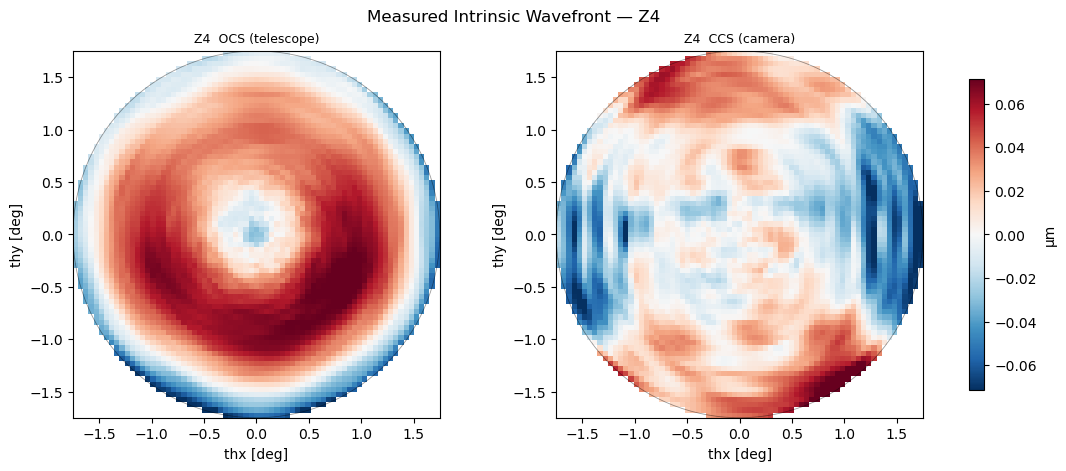

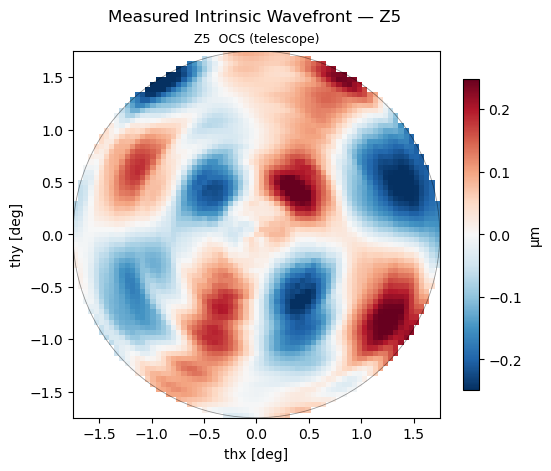

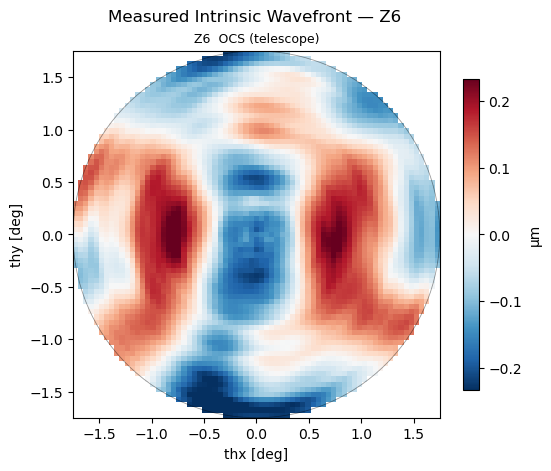

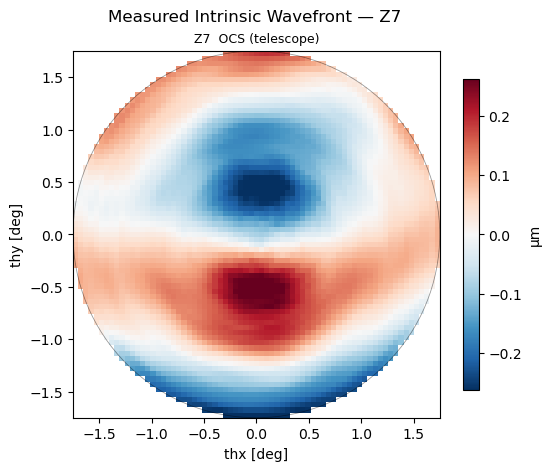

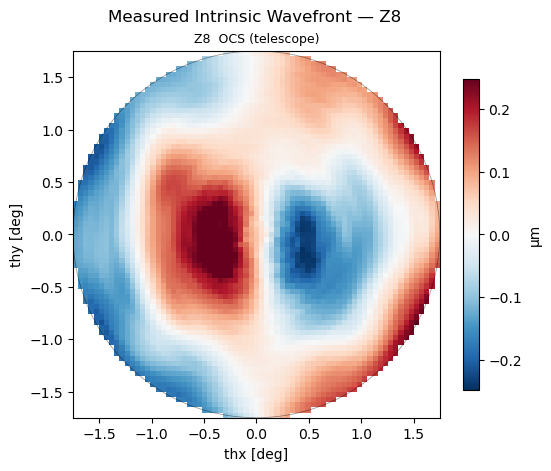

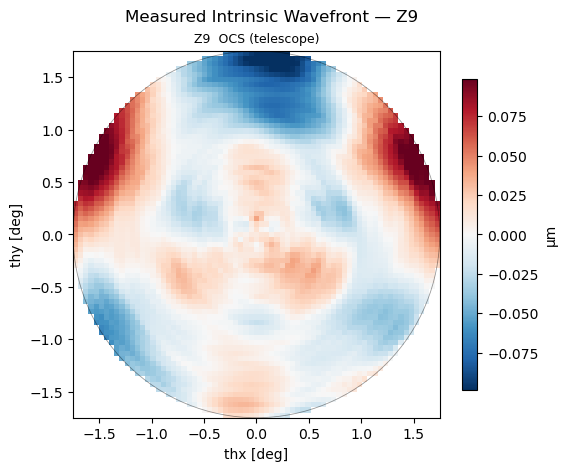

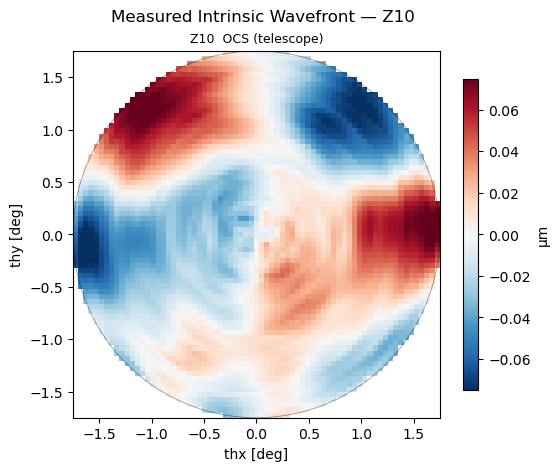

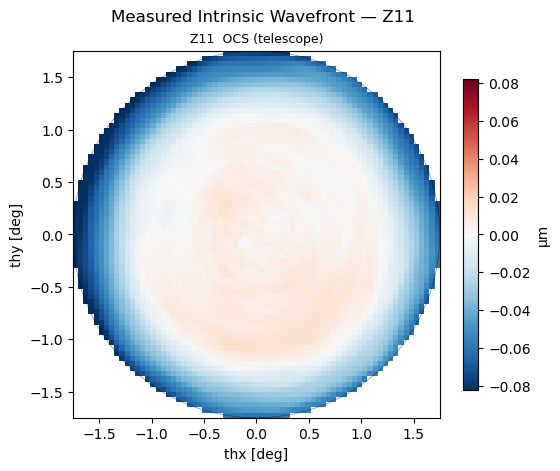

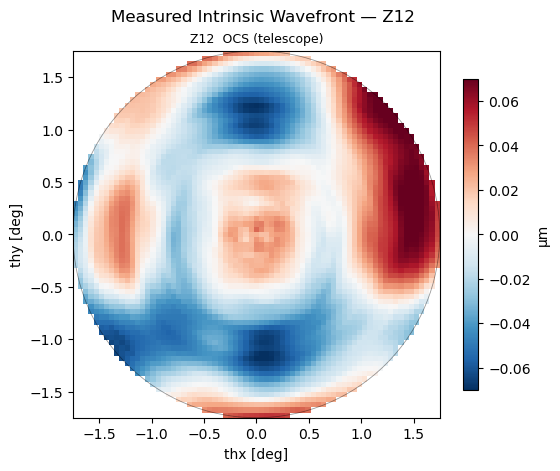

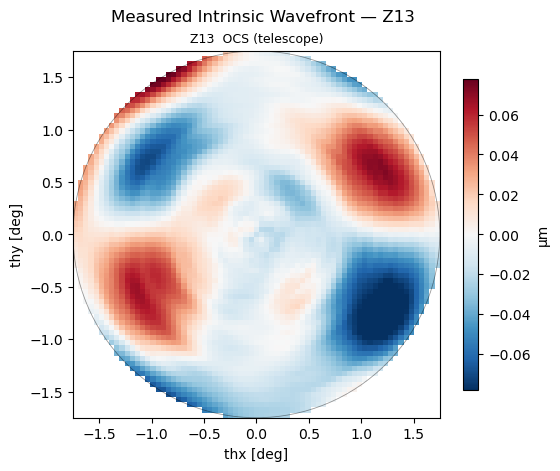

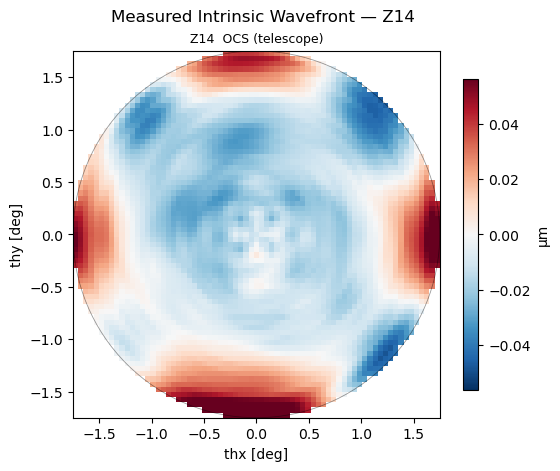

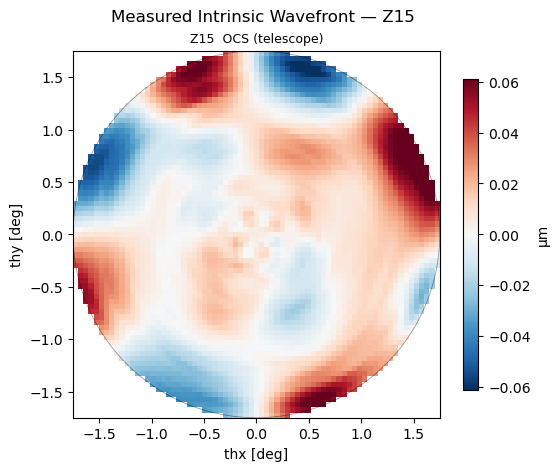

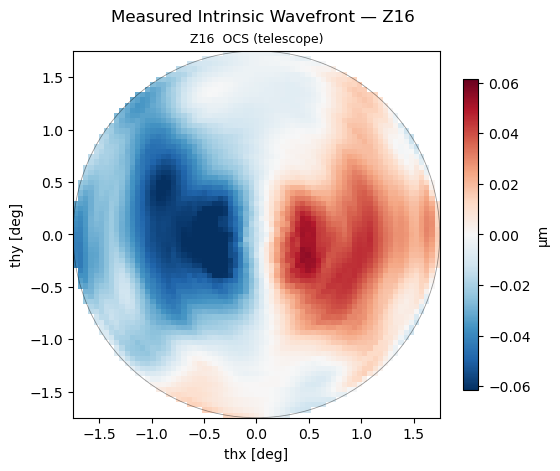

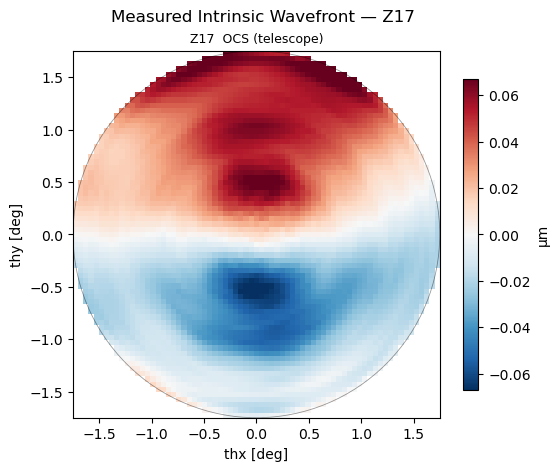

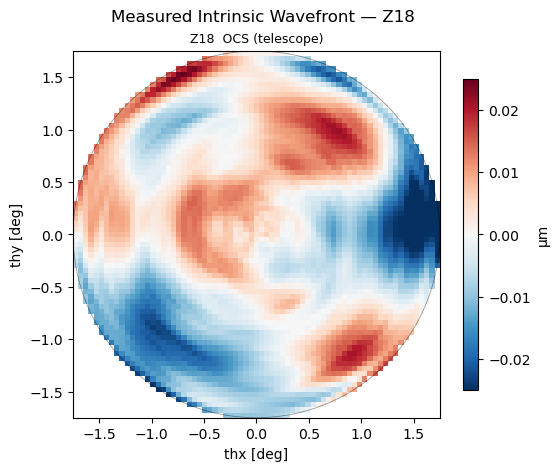

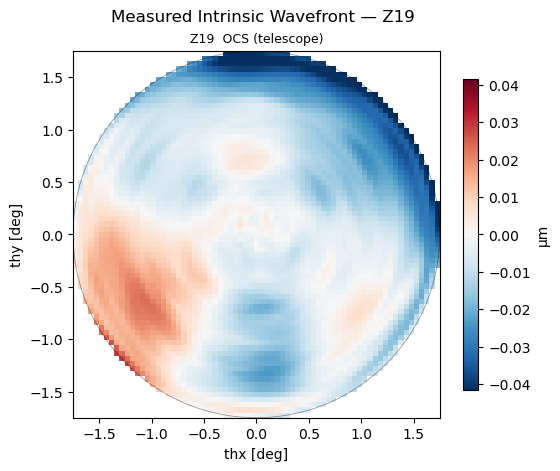

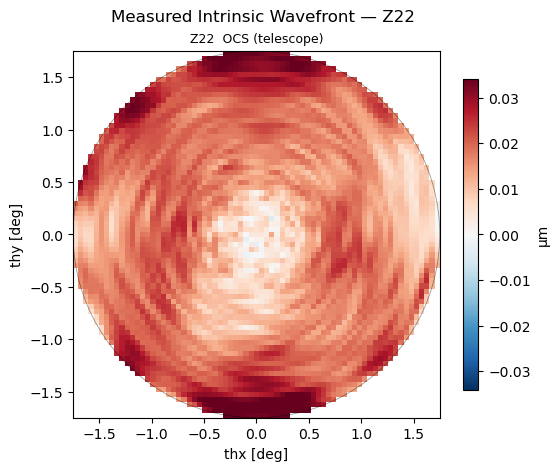

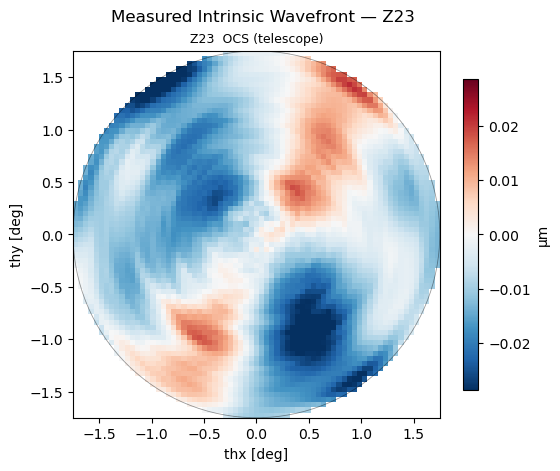

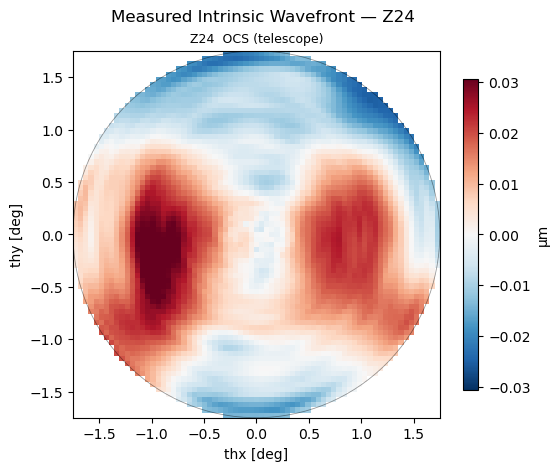

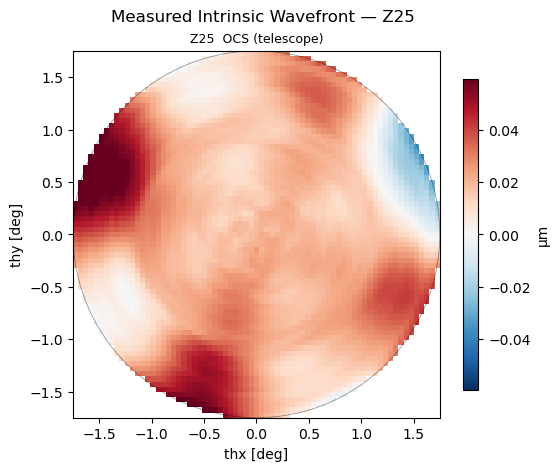

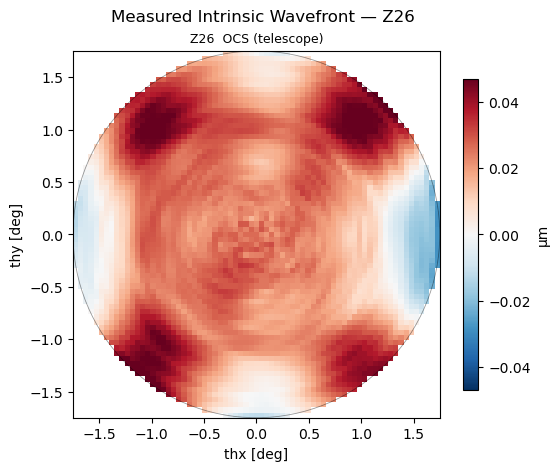

In [4]:
for j in js:
    O = np.asarray(t[f"Z{j}_OCS"], dtype=float)
    if j in ocs_only:
        fig, ax = plt.subplots(figsize=(5.8, 4.6), layout="constrained")
        tcf = plot_map(ax, O, f"Z{j}  OCS (telescope)", vlim_for(O))
        fig.colorbar(tcf, ax=ax, shrink=0.85, label="µm")
    else:
        C = np.asarray(t[f"Z{j}_CCS"], dtype=float)
        vlim = vlim_for(O, C)
        fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
        tcf = plot_map(axs[0], O, f"Z{j}  OCS (telescope)", vlim)
        plot_map(axs[1], C, f"Z{j}  CCS (camera)", vlim)
        fig.colorbar(tcf, ax=axs, shrink=0.85, label="µm")
    fig.suptitle(f"Measured Intrinsic Wavefront — Z{j}", fontsize=12)
    plt.show()

## 4b. Z4 at CCD resolution: CCS, and OCS + CCS
The build fits the smooth camera-fixed Z4 to the measured Z4 minus the CCD height term, so
`Z4_CCS` in the maps is smooth. The full camera-fixed Z4 is `Z4_CCS` plus the batoid CCD height
times `height_to_z4`, which is what the calibration tables carry. Here both are sampled on an
`n_ccd_grid` x `n_ccd_grid` grid over each science CCD and corner wavefront sensor (CWFS) half, and drawn CCD by CCD.
The CWFS reach 1.85 deg of field radius and the maps stop at 1.75 deg, so the smooth CCS and the
OCS are blank on the outer part of each CWFS; the height term covers all of it.

At camera rotator angle θ the measured Z4 is `O(r, φ) + C(r, φ - s·θ)`; Z4 has spin 0, so the
camera field only turns with the rotator. The CCD grid is fixed to the camera, so its OCS
position at θ is the CCS position rotated by `s·θ`.

  ccd_height_map dir: /sdf/group/rubin/u/roodman/LSST/packages/batoid_rubin_data/ccd_height_map


  CCD heights (batoid_rubin): intra/extra average -> Z4_height n_finite=435600/435600  (factor=15 μm/mm)


/lscratch/roodman/ipykernel_2501389/926140126.py:62: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax.pcolormesh(X, Y, v, cmap=cmap, vmin=-vlim, vmax=vlim,


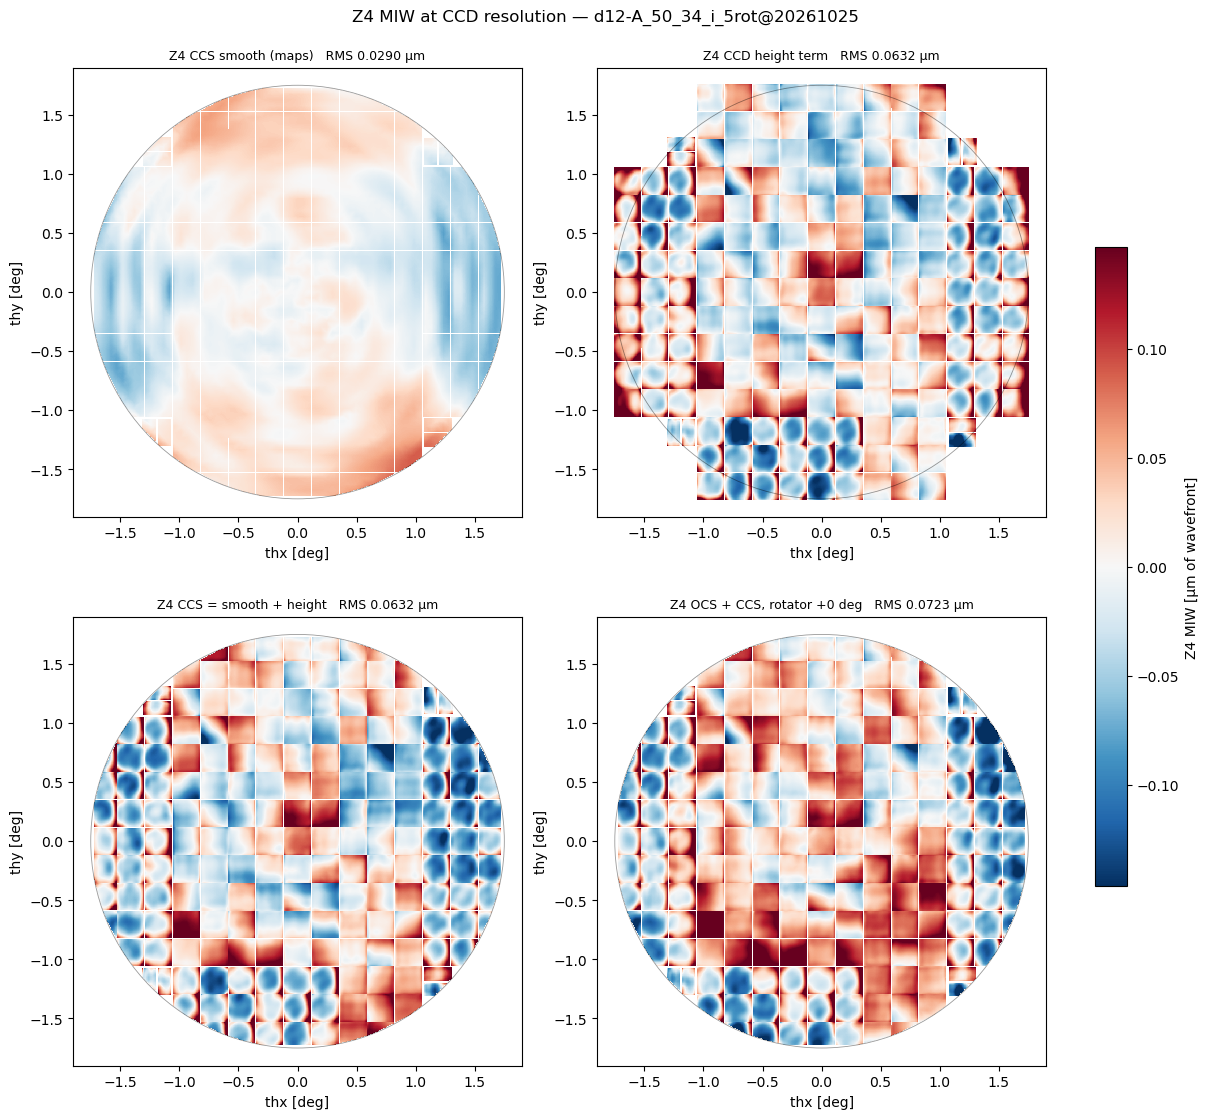

In [5]:
import pandas as pd
from lsst.obs.lsst import LsstCam
from lsst.afw.cameraGeom import FIELD_ANGLE, PIXELS, DetectorType
from lsst.ts.intrinsic.wavefront import ccd_height

camera = LsstCam.getCamera()
ccd = []        # per science CCD and CWFS half: name and its CCS field-angle grid
for det in camera:
    if det.getType() not in (DetectorType.SCIENCE, DetectorType.WAVEFRONT):
        continue
    bb = det.getBBox()
    ny = max(2, round(n_ccd_grid * bb.getHeight() / bb.getWidth()))   # CWFS: half height
    px, py = np.meshgrid(np.linspace(bb.getMinX(), bb.getMaxX(), n_ccd_grid),
                         np.linspace(bb.getMinY(), bb.getMaxY(), ny))
    fa = np.degrees(det.getTransform(PIXELS, FIELD_ANGLE).getMapping()
                    .applyForward(np.vstack([px.ravel(), py.ravel()])))
    # the maps use thx = FIELD_ANGLE y, thy = FIELD_ANGLE x
    ccd.append(dict(name=det.getName(), px=px.ravel(), py=py.ravel(),
                    x=fa[1].reshape(px.shape), y=fa[0].reshape(px.shape)))

pts = pd.DataFrame({"detector": np.concatenate([[c["name"]] * c["px"].size for c in ccd]),
                    "centroid_x_intra": np.concatenate([c["px"] for c in ccd]),
                    "centroid_y_intra": np.concatenate([c["py"] for c in ccd])})
pts["centroid_x_extra"], pts["centroid_y_extra"] = pts.centroid_x_intra, pts.centroid_y_intra
z4_height = ccd_height.compute_ccd_heights(pts, camera, source="batoid_rubin",
                                           height_map_dir=height_map_dir,
                                           factor=height_to_z4)["Z4_height"]
pos = 0
for c in ccd:
    n = c["px"].size
    c["height"] = z4_height[pos:pos + n].reshape(c["x"].shape)
    pos += n

s_rot = int(t.meta.get("rotation_sign", 1))


def _interp(col):
    v = np.asarray(t[col], dtype=float)
    fin = np.isfinite(v)
    return LinearNDInterpolator(np.column_stack([thx[fin], thy[fin]]), v[fin])


O4_interp, C4_interp = _interp("Z4_OCS"), _interp("Z4_CCS")
for c in ccd:
    c["ccs_smooth"] = C4_interp(c["x"], c["y"])
    c["ccs"] = c["ccs_smooth"] + c["height"]


def ocs_grid(c, th_deg):
    """OCS position of a CCD grid at rotator th_deg: CCS rotated by s*theta."""
    th = np.deg2rad(s_rot * th_deg)
    return (np.cos(th) * c["x"] - np.sin(th) * c["y"],
            np.sin(th) * c["x"] + np.cos(th) * c["y"])


def plot_ccds(ax, key_or_fn, title, vlim, th_deg=0.0, cmap="RdBu_r"):
    """Draw one value per CCD grid point, CCD by CCD, at its OCS position."""
    allv = []
    for c in ccd:
        v = key_or_fn(c) if callable(key_or_fn) else c[key_or_fn]
        X, Y = ocs_grid(c, th_deg)
        pcm = ax.pcolormesh(X, Y, v, cmap=cmap, vmin=-vlim, vmax=vlim,
                            shading="nearest", rasterized=True)
        allv.append(np.ravel(v))
    allv = np.concatenate(allv)
    _frame(ax, f"{title}   RMS {np.sqrt(np.nanmean(allv**2)):.4f} µm", lim=ccd_lim_deg)
    return pcm


def ccs_plus_ocs(th_deg):
    return lambda c: c["ccs"] + O4_interp(*ocs_grid(c, th_deg))


panels = [("ccs_smooth", "Z4 CCS smooth (maps)", 0.0),
          ("height", "Z4 CCD height term", 0.0),
          ("ccs", "Z4 CCS = smooth + height", 0.0)]
panels += [(ccs_plus_ocs(th), f"Z4 OCS + CCS, rotator {th:+.0f} deg", th) for th in z4_rotator_deg]
vlim = vlim_for(*[np.ravel(c["ccs"]) for c in ccd])
ncol = 2
nrow = int(np.ceil(len(panels) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(12, 5.6 * nrow), layout="constrained",
                        squeeze=False)
for ax, (key, title, th) in zip(axs.flat, panels):
    pcm = plot_ccds(ax, key, title, vlim, th_deg=th)
for ax in axs.flat[len(panels):]:
    ax.set_axis_off()
fig.colorbar(pcm, ax=axs, shrink=0.6, label="Z4 MIW [µm of wavefront]")
fig.suptitle(f"Z4 MIW at CCD resolution — {Path(maps_path).parent.parent.name}"
             f"@{Path(maps_path).parent.name}", fontsize=12)
plt.show()

## 4c. Overview pages: every Zernike of this MIW
One page of OCS maps for every Zernike, then one of CCS maps for the Zernikes with a CCS part (Z4 at CCD resolution, with the height term) plus Z4 OCS + CCS at rotator 0 deg, each with its own color scale. Saved
as a PDF in a dated run directory of this study (`miw_overview_<variant>_<build>.pdf`).

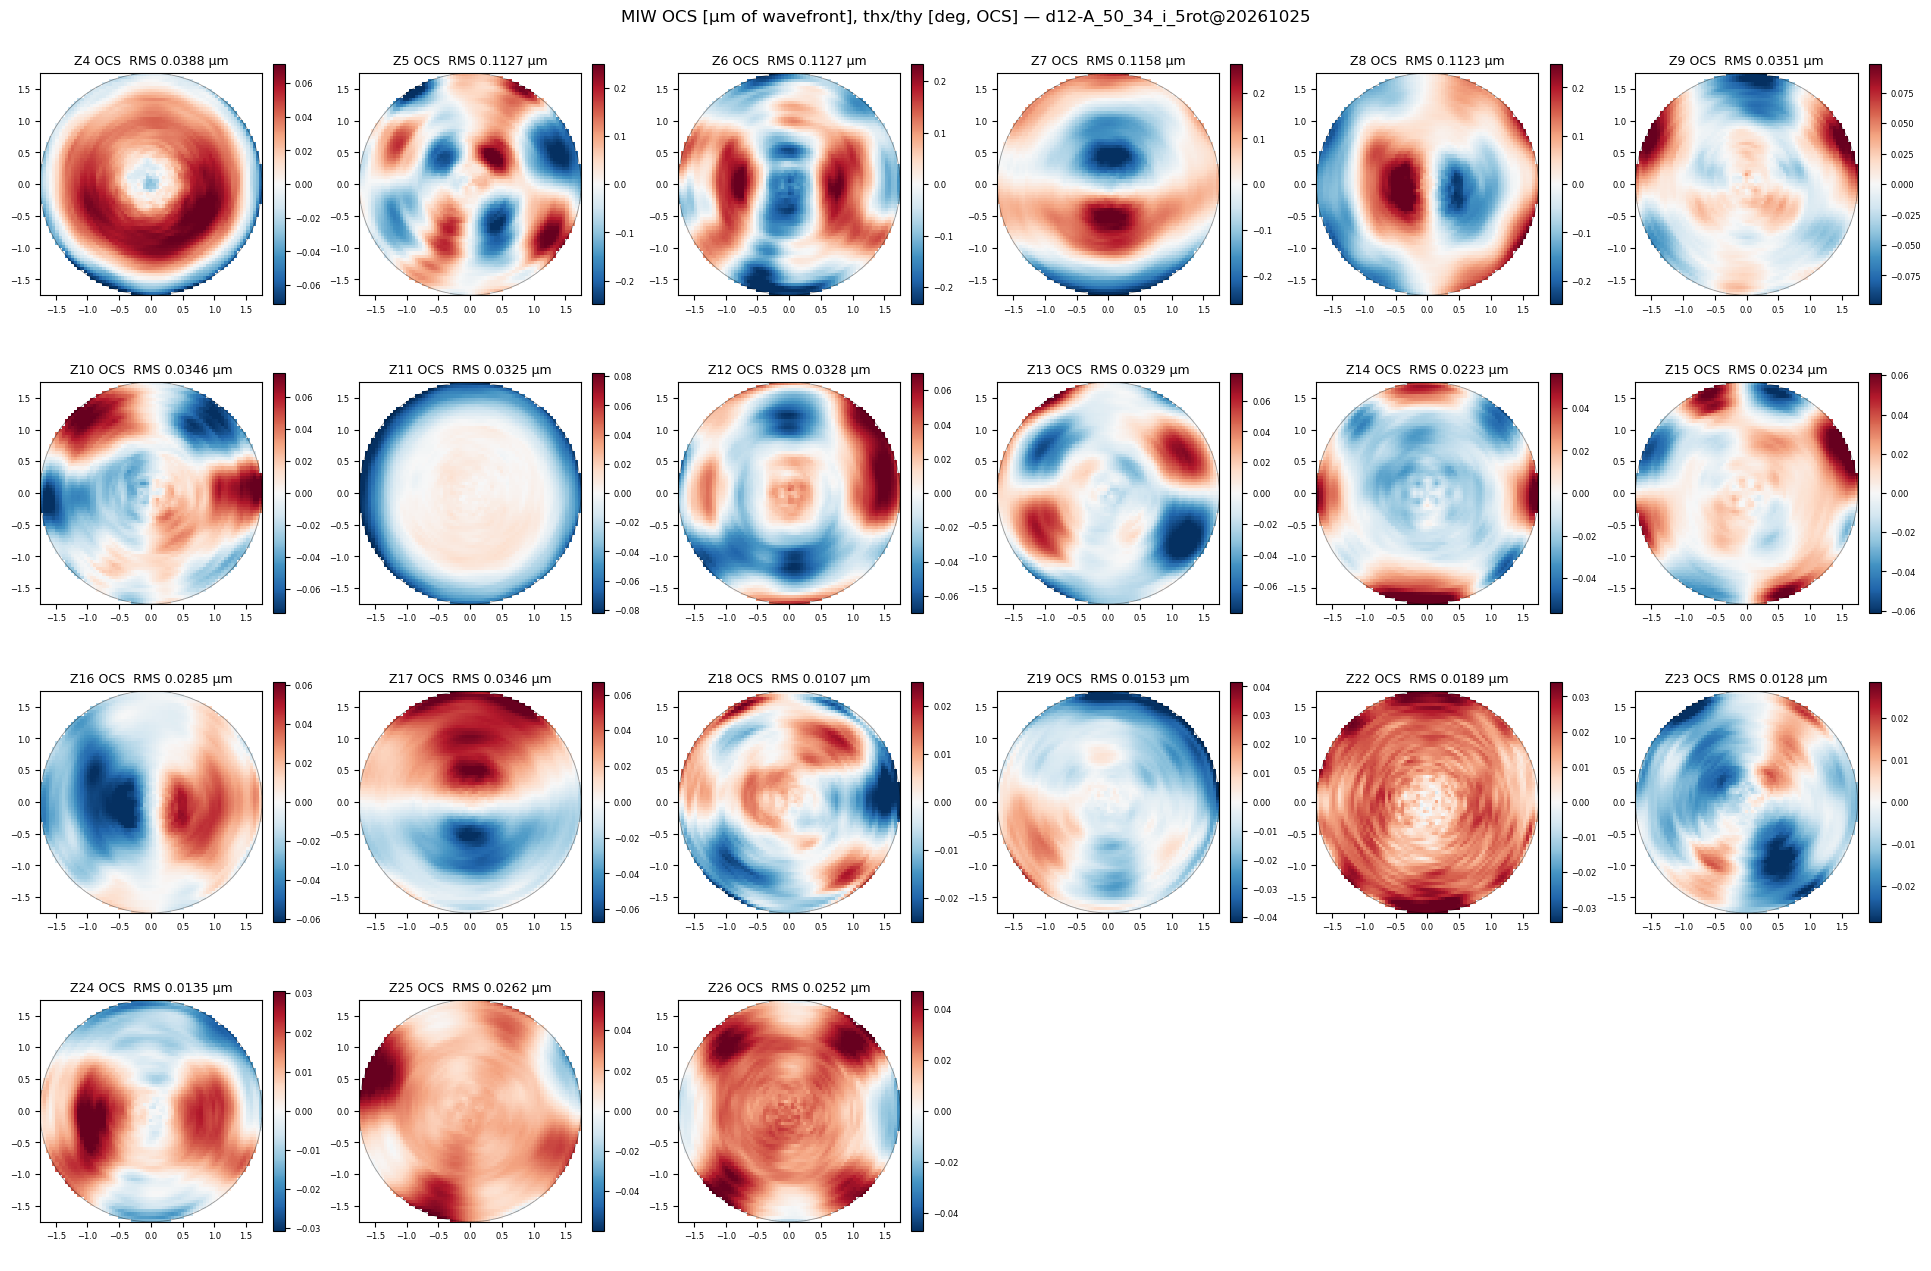

/lscratch/roodman/ipykernel_2501389/926140126.py:62: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax.pcolormesh(X, Y, v, cmap=cmap, vmin=-vlim, vmax=vlim,


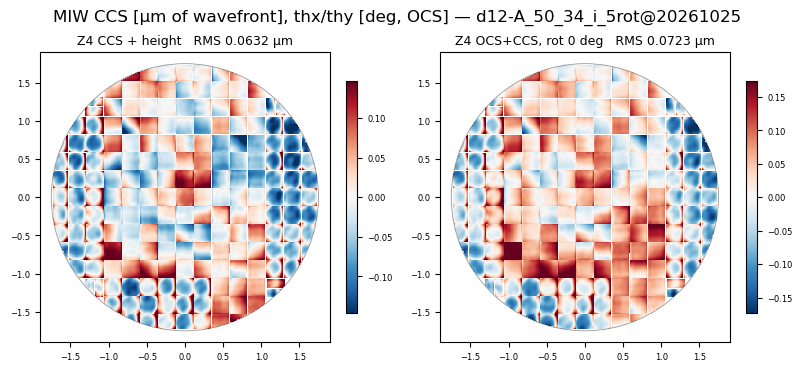

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/miw_version_comparisons/20261029_miw_overview/miw_overview_d12-A_50_34_i_5rot_20261025.pdf


In [6]:
from matplotlib.backends.backend_pdf import PdfPages
from rubinwork.common import study_run

tag = f"{Path(maps_path).parent.parent.name}@{Path(maps_path).parent.name}"
run = study_run("aos/miw_version_comparisons", "miw_overview")
pdf_path = run.path / f"miw_overview_{tag.replace('@', '_')}.pdf"

ncol = 6
pages = {"OCS": js, "CCS": [j for j in js if j not in ocs_only]}
if 4 in pages["CCS"]:
    pages["CCS"].insert(pages["CCS"].index(4) + 1, "Z4sum")
with PdfPages(pdf_path) as pdf:
    for frame, jf in pages.items():
        if not jf:
            continue
        nc = min(ncol, len(jf))
        nrow = int(np.ceil(len(jf) / nc))
        fig, axs = plt.subplots(nrow, nc, figsize=(max(3.2 * nc, 8), 3.0 * nrow + 0.6),
                                layout="constrained", squeeze=False)
        for ax, j in zip(axs.flat, jf):
            if j == "Z4sum":                # Z4 OCS + CCS + height, rotator 0 deg
                tcf = plot_ccds(ax, ccs_plus_ocs(0.0), "Z4 OCS+CCS, rot 0 deg",
                                vlim_for(*[np.ravel(ccs_plus_ocs(0.0)(c)) for c in ccd]))
            elif j == 4 and frame == "CCS":    # smooth CCS + CCD height
                tcf = plot_ccds(ax, "ccs", "Z4 CCS + height",
                                vlim_for(*[np.ravel(c["ccs"]) for c in ccd]))
            else:
                v = np.asarray(t[f"Z{j}_{frame}"], dtype=float)
                tcf = plot_map(ax, v, f"Z{j} {frame}  RMS {np.sqrt(np.nanmean(v**2)):.4f} µm",
                               vlim_for(v))
            ax.set_xlabel(""); ax.set_ylabel("")
            ax.tick_params(labelsize=6)
            fig.colorbar(tcf, ax=ax, shrink=0.8).ax.tick_params(labelsize=6)
        for ax in axs.flat[len(jf):]:
            ax.set_axis_off()
        fig.suptitle(f"MIW {frame} [µm of wavefront], thx/thy [deg, OCS] — {tag}",
                     fontsize=12)
        pdf.savefig(fig)
        plt.show()
print(pdf_path)

## 5. Reference values for the AOS online system

For a fixed field point at radius `r_query_deg` (here 1.7°) this tabulates, for **every** Zernike,
its **OCS** (telescope-fixed) part, its **CCS** (camera-fixed) part, and the **total** measured
OCS-frame wavefront at several **rotator angles**. It is a check fixture: the online code that
consumes these maps should reproduce the `total@θ` column after applying its own CCS→OCS rotation.

The model matches the pipeline exactly (`s = +1`, the OCS→CCS = R(−θ) convention):

$$Z_j(\theta) \;=\; O_j \;+\; e^{\,i\,\mathrm{spin}\,s\,\theta}\;\; C_j\big(r,\;\varphi - s\theta\big)$$

where `O_j = Z{j}_OCS`, `C_j = Z{j}_CCS`, and a (cos, sin) doublet forms the **complex** field
`Z_cos + i·Z_sin` (cos → real part, sin → imaginary part). Two things happen as the rotator turns:
the camera-fixed field is sampled at the rotated azimuth `φ − sθ`, **and** the phase
`exp(i·spin·s·θ)` mixes the cos/sin members — that mixing *is* the CCS→OCS conversion to verify.
Scalar (m=0) terms have spin 0 (no cos/sin mixing, but the camera field still rotates in azimuth);
OCS-only terms have `C ≈ 0`, so their total is rotator-independent — a useful negative control.

In [7]:
from scipy.interpolate import LinearNDInterpolator

# ---- field point and rotator angles to evaluate (edit freely) ----
r_query_deg = 1.7                       # focal-plane radius (deg)
az_query_deg = 30.0                     # OCS azimuth of the field point (deg)
rotator_angles_deg = [-20.0, 0.0, 20.0]

# ---- conventions (must match the AOS pipeline; see the markdown above) ----
s = int(t.meta.get("rotation_sign", 1))   # field-rotation sense; OCS->CCS = R(-theta)
spin_sign = 1                              # doublet phase sign (pipeline default +1)

# Noll index -> (radial n, signed azimuthal m); spin = |m|, cos has m>0, sin m<0.
NOLL_NM = {4: (2, 0), 5: (2, -2), 6: (2, 2), 7: (3, -1), 8: (3, 1), 9: (3, -3),
           10: (3, 3), 11: (4, 0), 12: (4, 2), 13: (4, -2), 14: (4, 4), 15: (4, -4),
           16: (5, 1), 17: (5, -1), 18: (5, 3), 19: (5, -3), 20: (5, 5), 21: (5, -5),
           22: (6, 0), 23: (6, -2), 24: (6, 2), 25: (6, -4), 26: (6, 4)}


def miw_interpolator(j, frame="OCS"):
    """LinearNDInterpolator for Z{j}_{frame}: call f(thx_deg, thy_deg) -> value (µm)."""
    v = np.asarray(t[f"Z{j}_{frame}"], dtype=float)
    fin = np.isfinite(v)
    return LinearNDInterpolator(np.column_stack([thx[fin], thy[fin]]), v[fin])


_OCS = {j: miw_interpolator(j, "OCS") for j in js}
_CCS = {j: miw_interpolator(j, "CCS") for j in js}


def _v(interp, xq, yq):
    return float(np.asarray(interp(xq, yq)))


def reconstruct(thx_q, thy_q, theta_deg):
    """Measured OCS-frame Zernikes at field point (thx_q, thy_q), rotator theta_deg.

    Returns {j: (ocs, ccs_raw, ccs_at_theta, total)} in µm, where
        ocs          = O_j               (telescope-fixed; rotator-independent)
        ccs_raw      = C_j at the point   (camera-fixed value, theta=0 azimuth)
        ccs_at_theta = exp(i*spin*s*th) * C_j(r, phi - s*th)  converted to the OCS frame
        total        = ocs + ccs_at_theta (what the online code should reproduce)
    """
    th = np.deg2rad(theta_deg)
    r = np.hypot(thx_q, thy_q)
    phi = np.arctan2(thy_q, thx_q)
    xc, yc = r * np.cos(phi - s * th), r * np.sin(phi - s * th)   # CCS azimuth phi - s*th
    out, done = {}, set()
    for j in js:
        if j in done:
            continue
        n, m = NOLL_NM[j]
        if m == 0:                                  # scalar: spin 0, no cos/sin mixing
            O = _v(_OCS[j], thx_q, thy_q)
            craw = _v(_CCS[j], thx_q, thy_q)
            cth = _v(_CCS[j], xc, yc)               # camera field at rotated azimuth
            out[j] = (O, craw, cth, O + cth)
            done.add(j)
            continue
        k = next((p for p in js if NOLL_NM.get(p) == (n, -m)), None)
        if k is None:                               # unpaired term: treat like its own field
            O = _v(_OCS[j], thx_q, thy_q)
            craw = _v(_CCS[j], thx_q, thy_q)
            cth = np.exp(1j * spin_sign * abs(m) * s * th) * _v(_CCS[j], xc, yc)
            out[j] = (O, craw, cth.real, O + cth.real)
            done.add(j)
            continue
        jc, jsn = (j, k) if m > 0 else (k, j)       # cos member has m>0
        spin = abs(m)
        Ocplx = _v(_OCS[jc], thx_q, thy_q) + 1j * _v(_OCS[jsn], thx_q, thy_q)
        Craw = _v(_CCS[jc], thx_q, thy_q) + 1j * _v(_CCS[jsn], thx_q, thy_q)
        Cth = np.exp(1j * spin_sign * spin * s * th) * \
            (_v(_CCS[jc], xc, yc) + 1j * _v(_CCS[jsn], xc, yc))
        tot = Ocplx + Cth
        out[jc] = (Ocplx.real, Craw.real, Cth.real, tot.real)
        out[jsn] = (Ocplx.imag, Craw.imag, Cth.imag, tot.imag)
        done.update((jc, jsn))
    return out


# ---- build and print the reference table ----
xq = r_query_deg * np.cos(np.deg2rad(az_query_deg))
yq = r_query_deg * np.sin(np.deg2rad(az_query_deg))
print(f"Field point: (thx, thy) = ({xq:+.4f}, {yq:+.4f}) deg   "
      f"[r = {r_query_deg} deg, az = {az_query_deg} deg]")
print(f"Convention: s = {s:+d}, spin_sign = {spin_sign:+d};  "
      f"Z(theta) = O + exp(i*spin*s*theta) * C(r, phi - s*theta)\n")

recon = {th: reconstruct(xq, yq, th) for th in rotator_angles_deg}

cols = {"Zernike": [f"Z{j}" for j in js], "j": list(js),
        "spin": [abs(NOLL_NM[j][1]) for j in js],
        "OCS": [recon[rotator_angles_deg[0]][j][0] for j in js],
        "CCS_raw": [recon[rotator_angles_deg[0]][j][1] for j in js]}
for th in rotator_angles_deg:
    cols[f"CCS@{th:+.0f}"] = [recon[th][j][2] for j in js]
    cols[f"total@{th:+.0f}"] = [recon[th][j][3] for j in js]

ref = Table(cols)
for c in ref.colnames:
    if c not in ("Zernike", "j", "spin"):
        ref[c].format = "%+.4f"
if not np.all(np.isfinite(list(cols["OCS"]))):
    print("WARNING: some values are NaN — the field point is outside the sampled disk; "
          "reduce r_query_deg slightly (e.g. 1.65).\n")
ref.pprint(max_width=-1, max_lines=-1)

Field point: (thx, thy) = (+1.4722, +0.8500) deg   [r = 1.7 deg, az = 30.0 deg]
Convention: s = +1, spin_sign = +1;  Z(theta) = O + exp(i*spin*s*theta) * C(r, phi - s*theta)



Zernike  j  spin   OCS   CCS_raw CCS@-20 total@-20  CCS@+0 total@+0 CCS@+20 total@+20
------- --- ---- ------- ------- ------- --------- ------- -------- ------- ---------
     Z4   4    0 -0.0280 -0.0449 +0.0135   -0.0145 -0.0449  -0.0728 -0.0701   -0.0981
     Z5   5    2 -0.1857 +0.0000 +0.0000   -0.1857 +0.0000  -0.1857 +0.0000   -0.1857
     Z6   6    2 -0.0475 +0.0000 +0.0000   -0.0475 +0.0000  -0.0475 +0.0000   -0.0475
     Z7   7    1 +0.0865 +0.0000 +0.0000   +0.0865 +0.0000  +0.0865 +0.0000   +0.0865
     Z8   8    1 +0.1892 +0.0000 +0.0000   +0.1892 +0.0000  +0.1892 +0.0000   +0.1892
     Z9   9    3 +0.0991 +0.0000 +0.0000   +0.0991 +0.0000  +0.0991 +0.0000   +0.0991
    Z10  10    3 -0.0340 +0.0000 +0.0000   -0.0340 +0.0000  -0.0340 +0.0000   -0.0340
    Z11  11    0 -0.0673 +0.0000 +0.0000   -0.0673 +0.0000  -0.0673 +0.0000   -0.0673
    Z12  12    2 +0.0682 +0.0000 +0.0000   +0.0682 +0.0000  +0.0682 +0.0000   +0.0682
    Z13  13    2 +0.0209 +0.0000 +0.0000   +0.0209 +0.